# Christian Eriksen: the creator, in numbers

Christian Eriksen's Premier League seasons at Tottenham (2013/14 to 2019/20), compared with every midfielder in the
league. Official Opta season stats from the Premier League's stats API. The comparison window is his six full Spurs
seasons, 2013/14 to 2018/19 (he left for Inter in January 2020). "Regular" = 1,800+ minutes in a season.

Charts 1, 2, 3, 4 and 7 of the report: the career, the goals-plus-assists leaders, the minutes, his rank in every
season, and Eriksen against David Silva per 90.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
EXT = ROOT / "data" / "external"
DARK_THEME = os.environ.get("REPORT_THEME") == "dark"  # dark = black-background charts for the PDF; the README uses the light ones
FIGS = ROOT / "reports" / ("figures_dark" if DARK_THEME else "figures")
FIGS.mkdir(parents=True, exist_ok=True)

# Spurs navy for Eriksen, a lighter navy for secondary series
SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#7A8BB8", "#132257", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
BG, GRID, SPAN, HEAT, HEAT_HI = "white", "#ECEAE4", "#FBF3DC", [NAVY, SKY, "#E8F1FA", "#FFFFFF"], "white"
if DARK_THEME:  # Spurs navy page: Eriksen in white, others in muted navy
    SKY, NAVY, GREY, DARK, MUTED = "#8C9CC8", "#FFFFFF", "#4A5888", "#FFFFFF", "#B8C0D9"
    BG, GRID, SPAN, HEAT, HEAT_HI = "#132257", "#25356F", "#2A2F5A", ["#FFFFFF", "#8C9CC8", "#2A3B78", "#0D1840"], "#000000"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad, 2010/11 to 2019/20"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Anton (headlines) and Lato (text), bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Lato", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": DARK, "legend.labelcolor": DARK,
})


def fs(light, pdf):
    """Figure size: the README (light) size, or a narrower one for the PDF so the text prints larger on the page."""
    return pdf if DARK_THEME else light


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=18, color=DARK, family="Anton")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2011 -> '2011/12'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2019/20 (official Opta stats). Season = starting year."""
    d = pd.concat([pd.read_csv(EXT / "pl_midfielders_2010-2018.csv"), pd.read_csv(EXT / "pl_midfielders_2018-2020.csv")])
    d = d.drop_duplicates(["season", "id"])
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["through"] = p90(d.throughBalls)                          # through balls per 90
    d["box"] = p90(d.totalTouchesInOppositionBox)               # touches in the opposition box per 90
    d["dribbles"] = d.successfulDribbles + d.unsuccessfulDribbles
    d["dribble_pct"] = d.successfulDribbles / d.dribbles.where(d.dribbles > 0)
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
ERIKSEN, SILVA = "Christian Eriksen", "David Silva"
SPURS = range(2013, 2019)   # his six full Spurs seasons, 2013/14 to 2018/19 (he left in January 2020)
FINISH = {2013: "6th", 2014: "5th", 2015: "3rd", 2016: "2nd", 2017: "3rd", 2018: "4th", 2019: "6th"}  # Spurs league finish

In [2]:
D = load_opta()
E = D[D.name == ERIKSEN].sort_values("season")
W = D[D.season.isin(SPURS)]                     # the six-season window
R = load_opta(min_minutes=1800)
print(f"Eriksen at Spurs: {E.appearances.sum()} games, {E.goals.sum()} goals, {E.goalAssists.sum()} assists")
E[["season", "appearances", "timePlayed", "goals", "penaltyGoals", "goalAssists", "keyPassesAttemptAssists", "throughBalls", "setPiecesGoals"]]

Eriksen at Spurs: 226 games, 51 goals, 62 assists


,season,appearances,timePlayed,goals,penaltyGoals,goalAssists,keyPassesAttemptAssists,throughBalls,setPiecesGoals
779,2013,25,1983,7,0,8,60,7,1
971,2014,38,3139,10,0,2,82,23,3
1164,2015,35,2849,6,0,13,102,12,2
1368,2016,36,3164,8,0,15,97,20,0
1543,2017,37,3226,10,0,10,85,24,0
157,2018,35,2771,8,0,12,61,24,1
348,2019,20,1090,2,0,2,22,5,1


In [3]:
# Totals over the window, every Premier League midfielder
TOT = W.groupby("name").agg(goals=("goals", "sum"), pens=("penaltyGoals", "sum"), assists=("goalAssists", "sum"),
                            chances=("keyPassesAttemptAssists", "sum"), through=("throughBalls", "sum"),
                            minutes=("timePlayed", "sum"), setpiece=("setPiecesGoals", "sum"),
                            box=("totalTouchesInOppositionBox", "sum"), opp=("successfulPassesOppositionHalf", "sum"),
                            dribbles=("successfulDribbles", "sum"), defend=("tacklesWon", "sum"), inter=("interceptions", "sum"),
                            games=("appearances", "sum"), starts=("starts", "sum"), touches=("touches", "sum"))
TOT["npg"] = TOT.goals - TOT.pens; TOT["ga"] = TOT.npg + TOT.assists
for c in ["ga", "assists", "chances", "minutes", "setpiece", "games", "starts", "touches", "opp"]:
    print(c, TOT[c].sort_values(ascending=False).head(4).to_dict())

ga {'Christian Eriksen': 109, 'David Silva': 93, 'Mesut Özil': 84, 'Gylfi Sigurdsson': 76}
assists {'Christian Eriksen': 60, 'David Silva': 53, 'Mesut Özil': 52, 'Kevin De Bruyne': 45}
chances {'Christian Eriksen': 487, 'Mesut Özil': 469, 'David Silva': 409, 'Eden Hazard': 324}
minutes {'Christian Eriksen': 17132, 'Mark Noble': 15965, 'Fernandinho': 15633, 'Gylfi Sigurdsson': 15607}
setpiece {'Christian Eriksen': 7, 'Juan Mata': 6, 'Gylfi Sigurdsson': 6, 'Yaya Touré': 4}
games {'Christian Eriksen': 206, 'Gylfi Sigurdsson': 196, 'Jack Cork': 195, 'Fernandinho': 194}
starts {'Christian Eriksen': 196, 'Mark Noble': 188, 'Gylfi Sigurdsson': 176, 'Fernandinho': 176}
touches {'Fernandinho': 15191, 'Christian Eriksen': 15100, 'David Silva': 14660, 'Nemanja Matic': 13816}
opp {'David Silva': 7795, 'Mesut Özil': 7414, 'Fernandinho': 6924, 'Christian Eriksen': 6737}


In [4]:
# Rank in each season among regular midfielders (1 = best)
RANKS = {"creating": "Chances created", "assisting": "Assists", "scoring": "Non-penalty goals", "through": "Through balls",
         "passing": "Passes in the opposition half", "box": "Touches in the opposition box"}
for c in RANKS:
    R["r_" + c] = R.groupby("season")[c].rank(ascending=False, method="min")
R["n"] = R.groupby("season").id.transform("size")
RE = R[(R.name == ERIKSEN) & R.season.isin(SPURS)].set_index("season")
RE[["n"] + ["r_" + c for c in RANKS]]

,n,r_creating,r_assisting,r_scoring,r_through,r_passing,r_box
season,,,,,,,
2013,76,4.0,4.0,3.0,23.0,22.0,31.0
2014,81,7.0,54.0,9.0,10.0,13.0,22.0
2015,79,4.0,5.0,17.0,18.0,8.0,4.0
2016,74,2.0,2.0,9.0,7.0,13.0,20.0
2017,75,4.0,9.0,5.0,5.0,10.0,20.0
2018,72,10.0,2.0,6.0,3.0,8.0,26.0


In [5]:
# Per 90 over the window: midfielders with 6,000+ minutes
P = TOT[TOT.minutes >= 6000].copy()
P["npg90"] = P.npg / P.minutes * 90; P["cc90"] = P.chances / P.minutes * 90; P["a90"] = P.assists / P.minutes * 90
P["opp90"] = P.opp / P.minutes * 90; P["drb90"] = P.dribbles / P.minutes * 90; P["def90"] = (P.defend + P.inter) / P.minutes * 90
print(len(P), "midfielders with 6,000+ minutes")
P.loc[[ERIKSEN, SILVA], ["minutes", "npg90", "a90", "cc90", "opp90", "drb90", "def90"]].round(3)

105 midfielders with 6,000+ minutes


,minutes,npg90,a90,cc90,opp90,drb90,def90
name,,,,,,,
Christian Eriksen,17132,0.257,0.315,2.558,35.392,0.946,1.755
David Silva,14242,0.253,0.335,2.585,49.259,1.428,1.687


## Charts

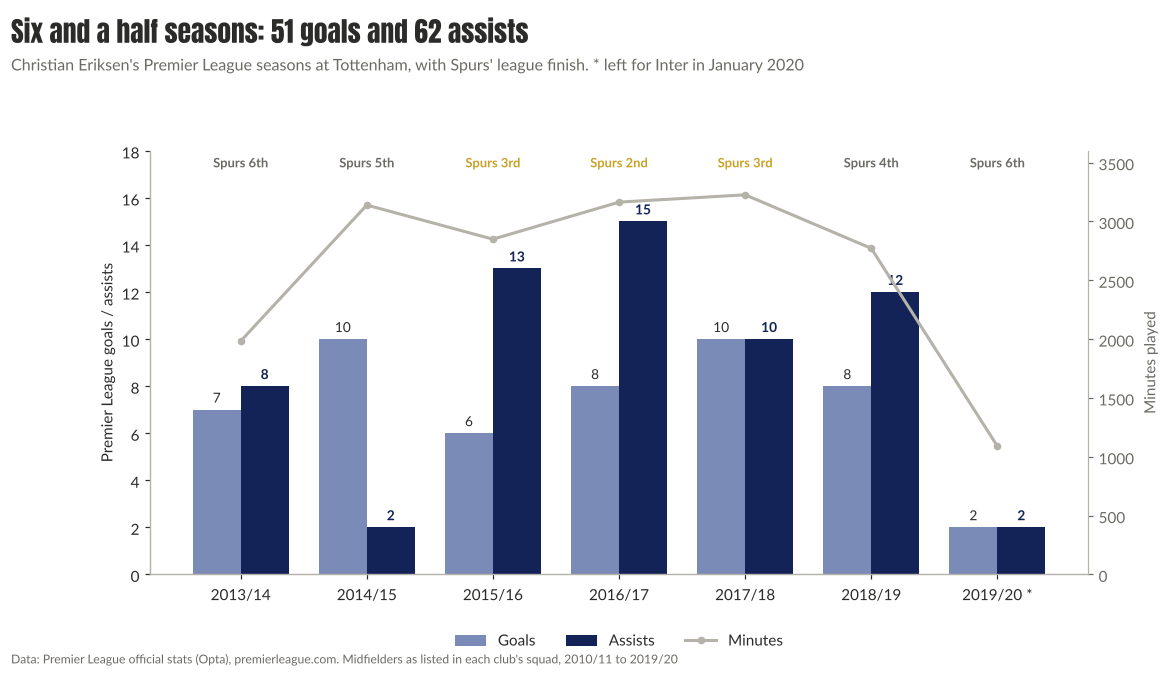

In [6]:
# Figure 1: seven seasons at Spurs
fig, ax = plt.subplots(figsize=fs((11, 5), (9.2, 4.6)))
x = np.arange(len(E)); w = 0.38
ax.bar(x - w / 2, E.goals, w, color=SKY, label="Goals")
ax.bar(x + w / 2, E.goalAssists, w, color=NAVY, label="Assists")
for xi, r in zip(x, E.itertuples()):
    ax.text(xi - w / 2, r.goals + 0.3, r.goals, ha="center", fontsize=9, color=DARK)
    ax.text(xi + w / 2, r.goalAssists + 0.3, r.goalAssists, ha="center", fontsize=9, color=NAVY, fontweight="bold")
    ax.text(xi, 17.3, f"Spurs {FINISH[r.season]}", ha="center", fontsize=8.5, color=GOLD if FINISH[r.season] in ("2nd", "3rd") else MUTED, fontweight="bold")
ax2 = ax.twinx(); ax2.plot(x, E.timePlayed, color=GREY, lw=2, marker="o", ms=4, label="Minutes"); ax2.set_ylim(0, 3600)
ax2.set_ylabel("Minutes played", color=MUTED); ax2.spines["right"].set_visible(True); ax2.tick_params(colors=MUTED)
labels = [season_label(s) + (" *" if s == 2019 else "") for s in E.season]
ax.set_xticks(x, labels); ax.set_ylim(0, 18); ax.set_ylabel("Premier League goals / assists")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
titles(fig, f"Six and a half seasons: {E.goals.sum()} goals and {E.goalAssists.sum()} assists",
       "Christian Eriksen's Premier League seasons at Tottenham, with Spurs' league finish. * left for Inter in January 2020", SRC_PL)
fig.savefig(FIGS / "01_career_by_season.png")

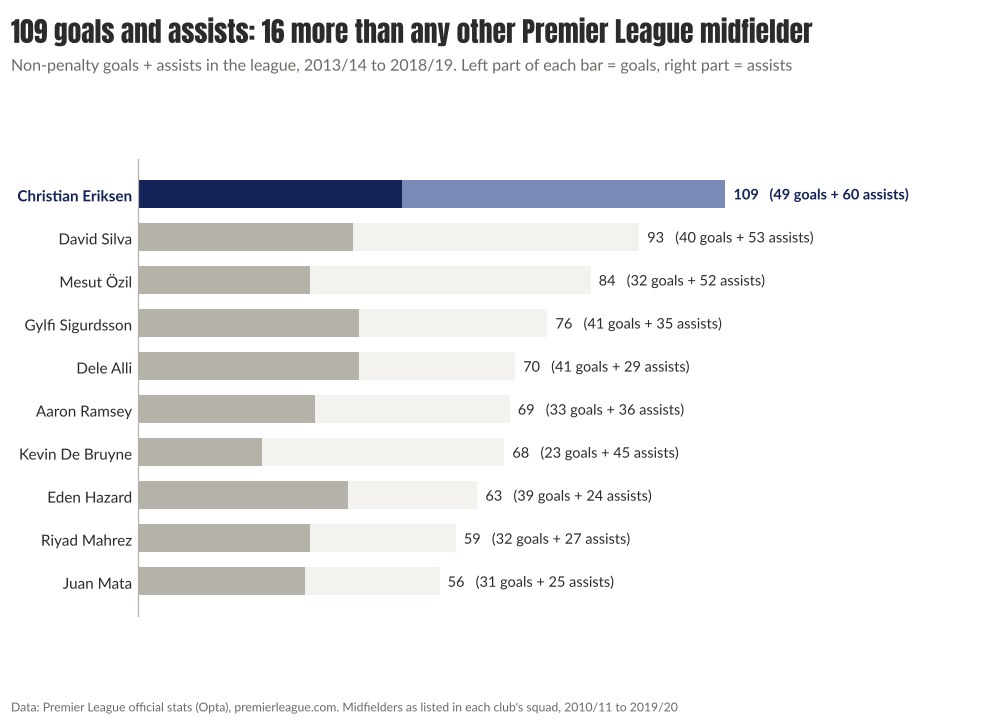

In [7]:
# Figure 2: goals + assists leaders over the window
top = TOT.sort_values("ga", ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=fs((10, 5.4), (9, 5.2)))
for i, (n, r) in enumerate(top.iterrows()):
    c1, c2 = (NAVY, SKY) if n == ERIKSEN else (GREY, LIGHT if not DARK_THEME else "#2F3E73")
    ax.barh(i, r.npg, color=c1, height=0.66); ax.barh(i, r.assists, left=r.npg, color=c2, height=0.66)
    ax.text(r.ga + 1.5, i, f"{int(r.ga)}   ({int(r.npg)} goals + {int(r.assists)} assists)", va="center", fontsize=9.5,
            color=NAVY if n == ERIKSEN else DARK, fontweight="bold" if n == ERIKSEN else "normal")
ax.set_yticks(range(len(top)), top.index, fontsize=10)
for lab in ax.get_yticklabels():
    if lab.get_text() == ERIKSEN: lab.set_color(NAVY); lab.set_fontweight("bold")
ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0); ax.set_xlim(0, top.ga.max() * 1.45)
r = TOT.loc[ERIKSEN]; second = TOT.ga.sort_values(ascending=False).iloc[1]
titles(fig, f"{int(r.ga)} goals and assists: {int(r.ga - second)} more than any other Premier League midfielder",
       "Non-penalty goals + assists in the league, 2013/14 to 2018/19. Left part of each bar = goals, right part = assists", SRC_PL)
fig.savefig(FIGS / "02_goals_and_assists.png")

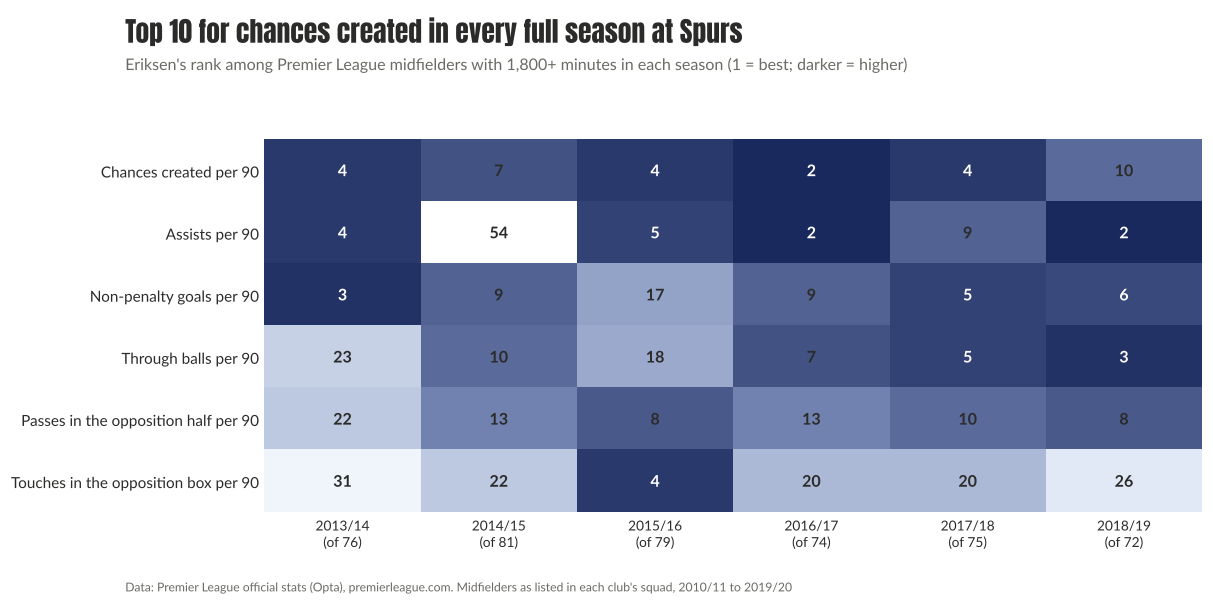

In [8]:
# Figure 4: rank in every season
M = RE[["r_" + c for c in RANKS]].T
fig, ax = plt.subplots(figsize=fs((11, 4.4), (9.6, 3.9)))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("rk", HEAT)
ax.imshow(np.clip(M.values, 1, 40), cmap=cmap, vmin=1, vmax=40, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = int(M.values[i, j])
        if DARK_THEME:
            r_, g_, b_, _ = cmap((min(v, 40) - 1) / 39); txt = "#000000" if 0.2126 * r_ + 0.7152 * g_ + 0.0722 * b_ > 0.25 else DARK
        else:
            txt = HEAT_HI if v <= 6 else DARK
        ax.text(j, i, v, ha="center", va="center", fontsize=10.5, fontweight="bold", color=txt)
ax.set_yticks(range(len(RANKS)), [RANKS[c[2:]] + " per 90" for c in M.index], fontsize=10)
ax.set_xticks(range(M.shape[1]), [f"{season_label(s)}\n(of {int(n)})" for s, n in zip(RE.index, RE.n)], fontsize=9)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
titles(fig, "Top 10 for chances created in every full season at Spurs",
       f"Eriksen's rank among Premier League midfielders with 1,800+ minutes in each season (1 = best; {'brighter' if DARK_THEME else 'darker'} = higher)", SRC_PL)
fig.savefig(FIGS / "04_rank_every_season.png")

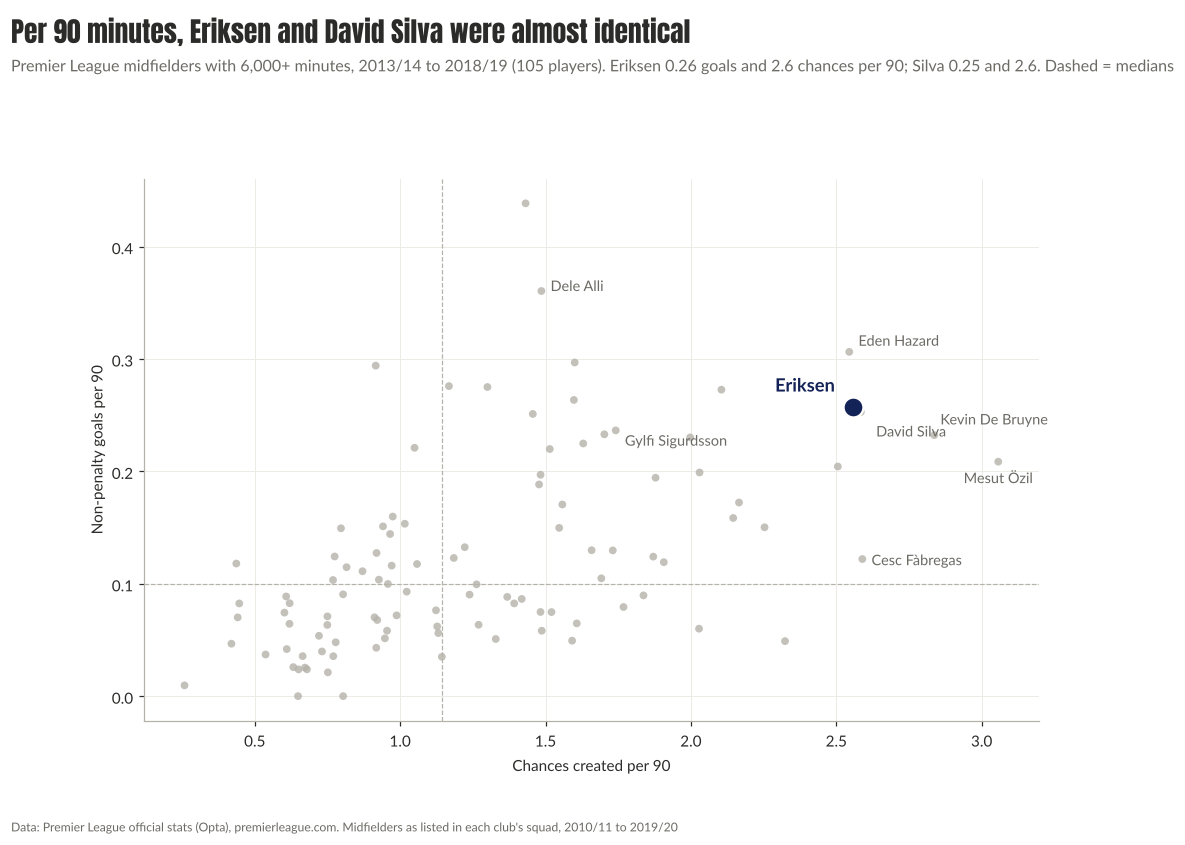

In [9]:
# Figure 7: Eriksen and Silva per 90
fig, ax = plt.subplots(figsize=fs((10.5, 6.4), (9, 6)))
o = P.drop([ERIKSEN]); ax.scatter(o.cc90, o.npg90, s=26, color=GREY, alpha=0.8, edgecolors="none")
r = P.loc[ERIKSEN]; ax.scatter(r.cc90, r.npg90, s=170, color=NAVY, edgecolors=BG, lw=1.5, zorder=3)
ax.annotate("Eriksen", (r.cc90, r.npg90), xytext=(-12, 10), textcoords="offset points", ha="right", color=NAVY, fontsize=12, fontweight="bold")
LAB = {"David Silva": (10, -16, "left"), "Mesut Özil": (0, -14, "center"), "Kevin De Bruyne": (4, 7, "left"), "Eden Hazard": (6, 4, "left"),
       "Dele Alli": (6, 0, "left"), "Cesc Fàbregas": (6, -4, "left"), "Gylfi Sigurdsson": (6, -10, "left")}
for n, (dx, dy, ha) in LAB.items():
    if n in P.index: ax.annotate(n, (P.loc[n].cc90, P.loc[n].npg90), xytext=(dx, dy), textcoords="offset points", ha=ha, color=MUTED, fontsize=9.5)
ax.axvline(P.cc90.median(), color=GREY, lw=0.8, ls="--"); ax.axhline(P.npg90.median(), color=GREY, lw=0.8, ls="--")
ax.set_xlabel("Chances created per 90"); ax.set_ylabel("Non-penalty goals per 90"); ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
s = P.loc[SILVA]
titles(fig, "Per 90 minutes, Eriksen and David Silva were almost identical",
       f"Premier League midfielders with 6,000+ minutes, 2013/14 to 2018/19 ({len(P)} players). Eriksen {r.npg90:.2f} goals and {r.cc90:.1f} chances per 90; Silva {s.npg90:.2f} and {s.cc90:.1f}. Dashed = medians",
       SRC_PL)
fig.savefig(FIGS / "07_eriksen_and_silva.png")

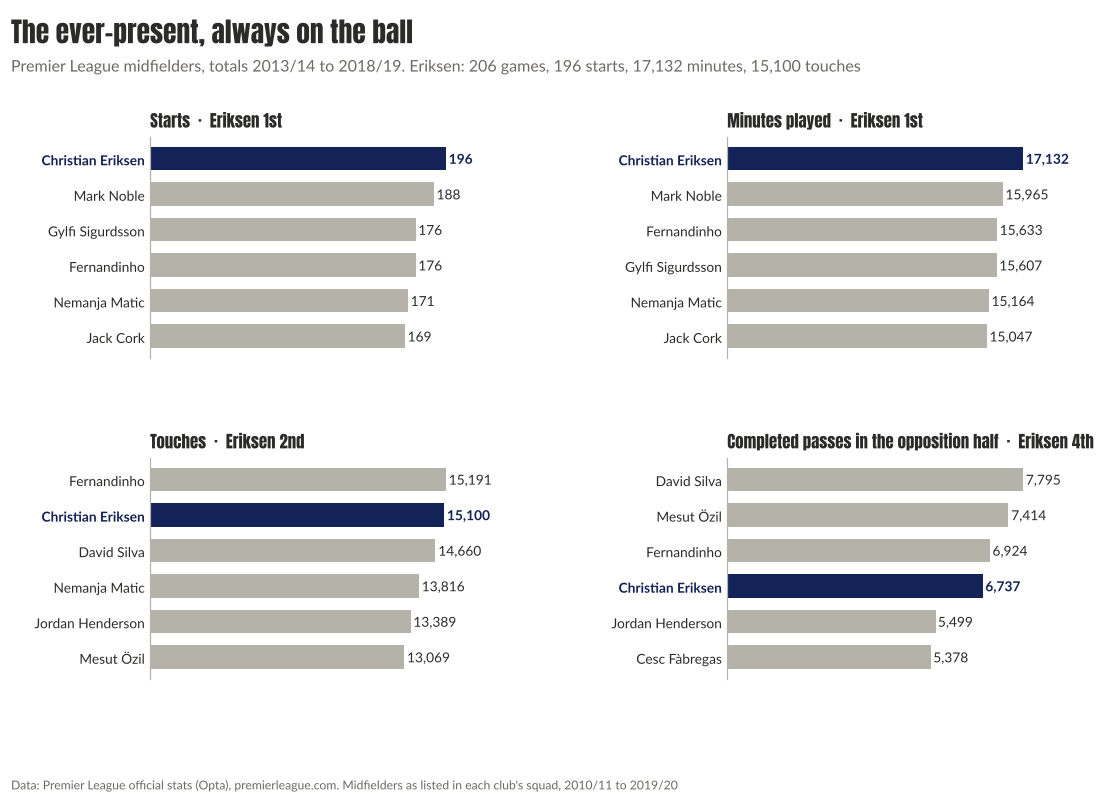

In [10]:
# Figure 3: the ever-present, and always on the ball (four leaderboards)
PANELS = [("starts", "Starts"), ("minutes", "Minutes played"), ("touches", "Touches"), ("opp", "Completed passes in the opposition half")]
fig, axes = plt.subplots(2, 2, figsize=fs((11, 6.4), (9.6, 6.2)))
for ax, (c, lab) in zip(axes.flat, PANELS):
    top = TOT[c].sort_values(ascending=False).head(6)
    if ERIKSEN not in top.index:
        top = pd.concat([top.head(5), TOT[c].loc[[ERIKSEN]]])
    top = top[::-1]; rank = int(TOT[c].rank(ascending=False, method="min")[ERIKSEN])
    ax.barh(range(len(top)), top.values, color=[NAVY if n == ERIKSEN else GREY for n in top.index], height=0.66)
    for i, (n, v) in enumerate(top.items()):
        ax.text(v * 1.01, i, f"{int(v):,}", va="center", fontsize=9, color=NAVY if n == ERIKSEN else DARK, fontweight="bold" if n == ERIKSEN else "normal")
    ax.set_yticks(range(len(top)), top.index, fontsize=9)
    for l in ax.get_yticklabels():
        if l.get_text() == ERIKSEN: l.set_color(NAVY); l.set_fontweight("bold")
    ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0); ax.set_xlim(0, top.max() * 1.22)
    ax.set_title(f"{lab}  ·  Eriksen {rank}{'st' if rank == 1 else 'nd' if rank == 2 else 'rd' if rank == 3 else 'th'}", loc="left", fontsize=11, color=DARK, family="Anton")
fig.subplots_adjust(hspace=0.45, wspace=0.6)
r = TOT.loc[ERIKSEN]
titles(fig, "The ever-present, always on the ball",
       f"Premier League midfielders, totals 2013/14 to 2018/19. Eriksen: {int(r.games)} games, {int(r.starts)} starts, {int(r.minutes):,} minutes, {int(r.touches):,} touches", SRC_PL, y=1.0)
fig.savefig(FIGS / "03_ever_present.png")